In [5]:
import sys

print(sys.executable)

c:\Users\Admin\Documents\Utech\Proyectos\financial-options-pricing-engine\.venv\Scripts\python.exe


# Interest Rate & Bond Modeling Engine

## Quantitative Fixed-Income Analysis with Python

This notebook presents a complete quantitative analysis of fixed-income instruments, including:

- Zero-coupon and fixed-coupon bond pricing
- Cash-flow schedules
- Current yield and Yield to Maturity (YTM)
- Macaulay and modified duration
- Convexity and DV01
- Spot and forward rates
- Zero-coupon yield-curve construction
- Yield-curve bootstrapping
- Vasicek interest-rate simulation
- Cox-Ingersoll-Ross interest-rate simulation
- Fixed-income risk visualizations

**Author:** Alexander Carrillo Reyes  
**Project:** Quantitative Finance Portfolio  
**Language:** Python  
**Version:** 1.0.0

---

> This project is intended for educational and quantitative research purposes.  
> It does not constitute financial or investment advice.

In [6]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "src").exists():
    for parent in Path.cwd().resolve().parents:
        if (parent / "src").exists():
            project_root = parent
            break

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.bond_pricing import (
    BondParameters,
    generate_cash_flows,
    price_coupon_bond,
    price_zero_coupon_bond,
)
from src.duration_convexity import (
    calculate_duration_convexity_metrics,
    estimate_new_bond_price,
)
from src.rate_models import (
    CIRParameters,
    VasicekParameters,
    cir_feller_condition,
    simulate_cir,
    simulate_vasicek,
    summarize_simulation,
)
from src.visualization import (
    plot_duration_convexity_approximation,
    plot_price_yield_relationship,
    plot_rate_paths,
    plot_rate_percentile_bands,
    plot_yield_curve,
)
from src.yield_curve import (
    build_yield_curve,
    calculate_forward_rate,
    interpolate_spot_rate,
)
from src.yield_metrics import (
    calculate_yield_metrics,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = "{:,.6f}".format

print(f"Python executable: {sys.executable}")
print(f"Project root: {project_root}")
print("Fixed-income modules imported successfully.")

Python executable: c:\Users\Admin\Documents\Utech\Proyectos\financial-options-pricing-engine\.venv\Scripts\python.exe
Project root: C:\Users\Admin\Documents\Utech\Proyectos\interest-rate-bond-modeling-engine
Fixed-income modules imported successfully.


## 1. Fixed-Coupon Bond Valuation

A fixed-rate bond represents a sequence of future cash flows:

1. Periodic coupon payments.
2. Repayment of the face value at maturity.

The theoretical price is the present value of all promised cash flows:

\[
P =
\sum_{t=1}^{N}
\frac{C}{\left(1+\frac{y}{m}\right)^t}
+
\frac{F}{\left(1+\frac{y}{m}\right)^N}
\]

where:

- \(P\) is the bond price.
- \(C\) is the coupon paid during each period.
- \(F\) is the face value.
- \(y\) is the nominal annual yield.
- \(m\) is the number of payments per year.
- \(N\) is the total number of payment periods.

If the coupon rate exceeds the market yield, the bond trades at a **premium**.  
If the coupon rate is below the market yield, it trades at a **discount**.

In [8]:
bond = BondParameters(
    face_value=1_000.0,
    annual_coupon_rate=0.05,
    years_to_maturity=5.0,
    payments_per_year=2,
)

market_yield = 0.04

coupon_bond_price = price_coupon_bond(
    parameters=bond,
    annual_yield=market_yield,
)

zero_coupon_price = price_zero_coupon_bond(
    face_value=bond.face_value,
    annual_yield=market_yield,
    years_to_maturity=bond.years_to_maturity,
    compounding_frequency=bond.payments_per_year,
)

print("Bond valuation")
print(f"Face value: ${bond.face_value:,.2f}")
print(f"Annual coupon rate: {bond.annual_coupon_rate:.2%}")
print(f"Market yield: {market_yield:.2%}")
print(f"Coupon payment: ${bond.coupon_payment:,.2f}")
print(f"Number of payments: {bond.number_of_payments}")
print(f"Fixed-coupon bond price: ${coupon_bond_price:,.2f}")
print(f"Zero-coupon bond price: ${zero_coupon_price:,.2f}")

Bond valuation
Face value: $1,000.00
Annual coupon rate: 5.00%
Market yield: 4.00%
Coupon payment: $25.00
Number of payments: 10
Fixed-coupon bond price: $1,044.91
Zero-coupon bond price: $820.35


In [9]:
cash_flows = generate_cash_flows(bond)

cash_flow_table = pd.DataFrame(
    {
        "Payment": [
            cash_flow.payment_number
            for cash_flow in cash_flows
        ],
        "Time (years)": [
            cash_flow.time_in_years
            for cash_flow in cash_flows
        ],
        "Coupon": [
            cash_flow.coupon_payment
            for cash_flow in cash_flows
        ],
        "Principal": [
            cash_flow.principal_payment
            for cash_flow in cash_flows
        ],
        "Total payment": [
            cash_flow.total_payment
            for cash_flow in cash_flows
        ],
    }
)

cash_flow_table.style.format(
    {
        "Time (years)": "{:.1f}",
        "Coupon": "${:,.2f}",
        "Principal": "${:,.2f}",
        "Total payment": "${:,.2f}",
    }
)

,Payment,Time (years),Coupon,Principal,Total payment
0,1,0.5,$25.00,$0.00,$25.00
1,2,1.0,$25.00,$0.00,$25.00
2,3,1.5,$25.00,$0.00,$25.00
3,4,2.0,$25.00,$0.00,$25.00
4,5,2.5,$25.00,$0.00,$25.00
5,6,3.0,$25.00,$0.00,$25.00
6,7,3.5,$25.00,$0.00,$25.00
7,8,4.0,$25.00,$0.00,$25.00
8,9,4.5,$25.00,$0.00,$25.00
9,10,5.0,$25.00,"$1,000.00","$1,025.00"


## 2. Bond Yield Measures

Bond investors use several complementary yield measures.

### Current Yield

Current yield compares annual coupon income with the current market price:

\[
\text{Current Yield}
=
\frac{\text{Annual Coupon}}{\text{Market Price}}
\]

It ignores capital gains or losses and the time value of money.

### Yield to Maturity

Yield to Maturity (YTM) is the discount rate that equates the present value of all future cash flows with the observed market price:

\[
P =
\sum_{t=1}^{N}
\frac{C}{\left(1+\frac{YTM}{m}\right)^t}
+
\frac{F}{\left(1+\frac{YTM}{m}\right)^N}
\]

Because the YTM appears inside powers, it is generally calculated using a numerical root-finding algorithm.

### Effective Annual Yield

For a nominal YTM compounded \(m\) times per year:

\[
EAY =
\left(1+\frac{YTM}{m}\right)^m - 1
\]

In [10]:
observed_market_price = 950.0

yield_metrics = calculate_yield_metrics(
    parameters=bond,
    market_price=observed_market_price,
)

reconstructed_price = price_coupon_bond(
    parameters=bond,
    annual_yield=yield_metrics.yield_to_maturity,
)

yield_summary = pd.DataFrame(
    {
        "Metric": [
            "Observed market price",
            "Current yield",
            "Yield to maturity",
            "Effective annual yield",
            "Price reconstructed from YTM",
        ],
        "Value": [
            f"${observed_market_price:,.2f}",
            f"{yield_metrics.current_yield:.4%}",
            f"{yield_metrics.yield_to_maturity:.4%}",
            f"{yield_metrics.effective_annual_yield:.4%}",
            f"${reconstructed_price:,.2f}",
        ],
    }
)

yield_summary

,Metric,Value
0,Observed market price,$950.00
1,Current yield,5.2632%
2,Yield to maturity,6.1776%
3,Effective annual yield,6.2730%
4,Price reconstructed from YTM,$950.00


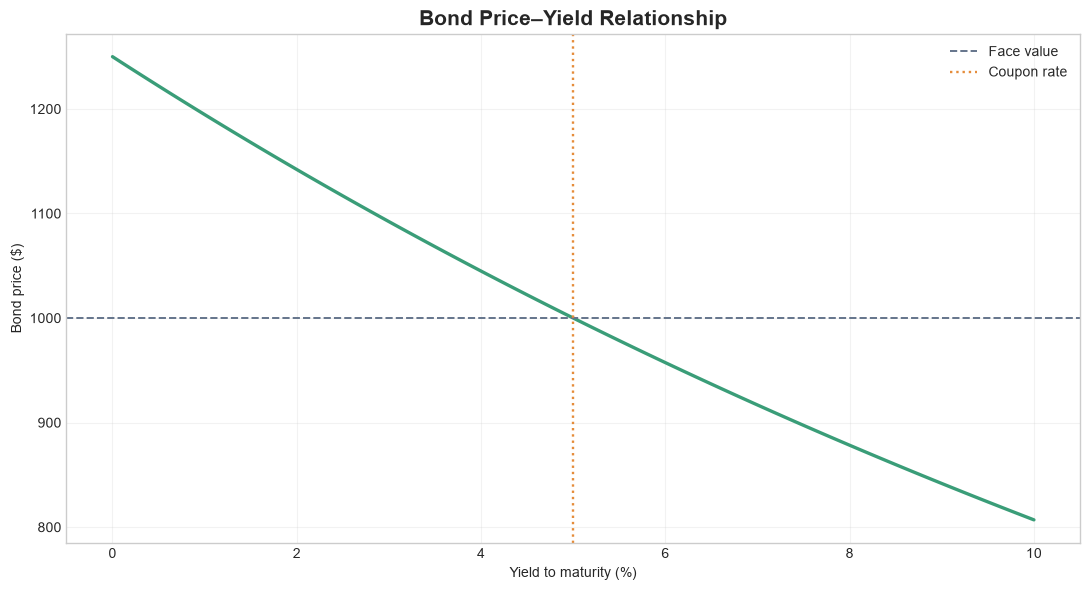

In [11]:
yield_range = np.linspace(
    0.00,
    0.10,
    101,
)

figure, axis = plot_price_yield_relationship(
    parameters=bond,
    annual_yields=yield_range,
)

plt.show()

## 3. Duration, Convexity, and DV01

Bond prices are sensitive to changes in market interest rates.

### Macaulay Duration

Macaulay duration is the present-value-weighted average time required to receive the bond's cash flows:

\[
D_{\text{Mac}}
=
\frac{
\sum_{t=1}^{N}
T_t \times PV(CF_t)
}{
P
}
\]

It is measured in years.

### Modified Duration

Modified duration estimates the percentage price change produced by a small change in yield:

\[
D_{\text{Mod}}
=
\frac{
D_{\text{Mac}}
}{
1+\frac{y}{m}
}
\]

The first-order price approximation is:

\[
\frac{\Delta P}{P}
\approx
-D_{\text{Mod}}\Delta y
\]

### Convexity

Duration is a linear approximation, but the price-yield relationship is curved. Convexity captures this curvature:

\[
\frac{\Delta P}{P}
\approx
-D_{\text{Mod}}\Delta y
+
\frac{1}{2}
\text{Convexity}
(\Delta y)^2
\]

### DV01

DV01 estimates the monetary price change caused by a one-basis-point movement in yield:

\[
DV01
=
P \times D_{\text{Mod}} \times 0.0001
\]

One basis point is equal to \(0.01\%\).

In [12]:
sensitivity_metrics = (
    calculate_duration_convexity_metrics(
        parameters=bond,
        annual_yield=market_yield,
    )
)

yield_shock = 0.01

estimated_price = estimate_new_bond_price(
    parameters=bond,
    annual_yield=market_yield,
    yield_change=yield_shock,
    include_convexity=True,
)

exact_repriced_value = price_coupon_bond(
    parameters=bond,
    annual_yield=market_yield + yield_shock,
)

sensitivity_summary = pd.DataFrame(
    {
        "Metric": [
            "Current bond price",
            "Macaulay duration",
            "Modified duration",
            "Convexity",
            "DV01",
            "Estimated price after +100 bps",
            "Exact price after +100 bps",
            "Approximation error",
        ],
        "Value": [
            f"${sensitivity_metrics.bond_price:,.2f}",
            f"{sensitivity_metrics.macaulay_duration:.6f} years",
            f"{sensitivity_metrics.modified_duration:.6f}",
            f"{sensitivity_metrics.convexity:.6f}",
            f"${sensitivity_metrics.dv01:,.4f}",
            f"${estimated_price:,.2f}",
            f"${exact_repriced_value:,.2f}",
            f"${estimated_price - exact_repriced_value:,.4f}",
        ],
    }
)

sensitivity_summary

,Metric,Value
0,Current bond price,"$1,044.91"
1,Macaulay duration,4.498904 years
2,Modified duration,4.410690
3,Convexity,22.923146
4,DV01,$0.4609
5,Estimated price after +100 bps,"$1,000.02"
6,Exact price after +100 bps,"$1,000.00"
7,Approximation error,$0.0227


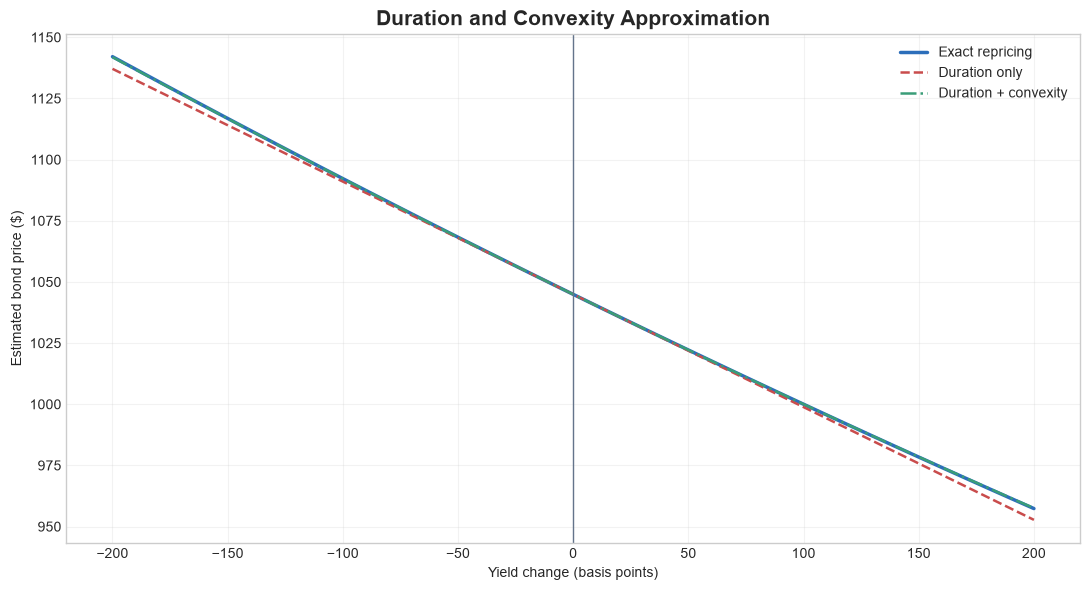

In [13]:
yield_changes = np.linspace(
    -0.02,
    0.02,
    81,
)

figure, axis = (
    plot_duration_convexity_approximation(
        parameters=bond,
        annual_yield=market_yield,
        yield_changes=yield_changes,
    )
)

plt.show()

## 4. Zero-Coupon Yield Curve and Forward Rates

A yield curve describes how interest rates vary across maturities.

Each point on a zero-coupon curve contains:

- A maturity.
- A spot rate.
- A discount factor.

For nominal compounding \(m\) times per year, the discount factor is:

\[
DF(0,T)
=
\frac{1}{
\left(1+\frac{s_T}{m}\right)^{mT}
}
\]

where \(s_T\) is the spot rate for maturity \(T\).

The present value of a future payment is:

\[
PV(CF_T)
=
CF_T \times DF(0,T)
\]

### Forward Rates

A forward rate is the future interest rate implied by today's spot-rate curve.

For maturities \(T_1<T_2\):

\[
\left(1+\frac{s_{T_2}}{m}\right)^{mT_2}
=
\left(1+\frac{s_{T_1}}{m}\right)^{mT_1}
\left(1+\frac{f_{T_1,T_2}}{m}\right)^{m(T_2-T_1)}
\]

Forward rates are implied market rates, not guaranteed forecasts.

In [14]:
maturities = (0.5, 1.0, 2.0, 3.0, 5.0)
spot_rates = (0.035, 0.037, 0.040, 0.042, 0.045)

yield_curve = build_yield_curve(
    maturities=maturities,
    spot_rates=spot_rates,
    compounding_frequency=2,
)

yield_curve_table = pd.DataFrame(
    {
        "Maturity (years)": [
            point.maturity_years
            for point in yield_curve
        ],
        "Spot rate": [
            point.spot_rate
            for point in yield_curve
        ],
        "Discount factor": [
            point.discount_factor
            for point in yield_curve
        ],
    }
)

yield_curve_table.style.format(
    {
        "Maturity (years)": "{:.1f}",
        "Spot rate": "{:.4%}",
        "Discount factor": "{:.6f}",
    }
)

,Maturity (years),Spot rate,Discount factor
0,0.5,3.5000%,0.982801
1,1.0,3.7000%,0.964002
2,2.0,4.0000%,0.923845
3,3.0,4.2000%,0.882766
4,5.0,4.5000%,0.800510


Interpolated four-year spot rate: 4.3500%
Implied two-to-five-year forward rate: 4.8340%


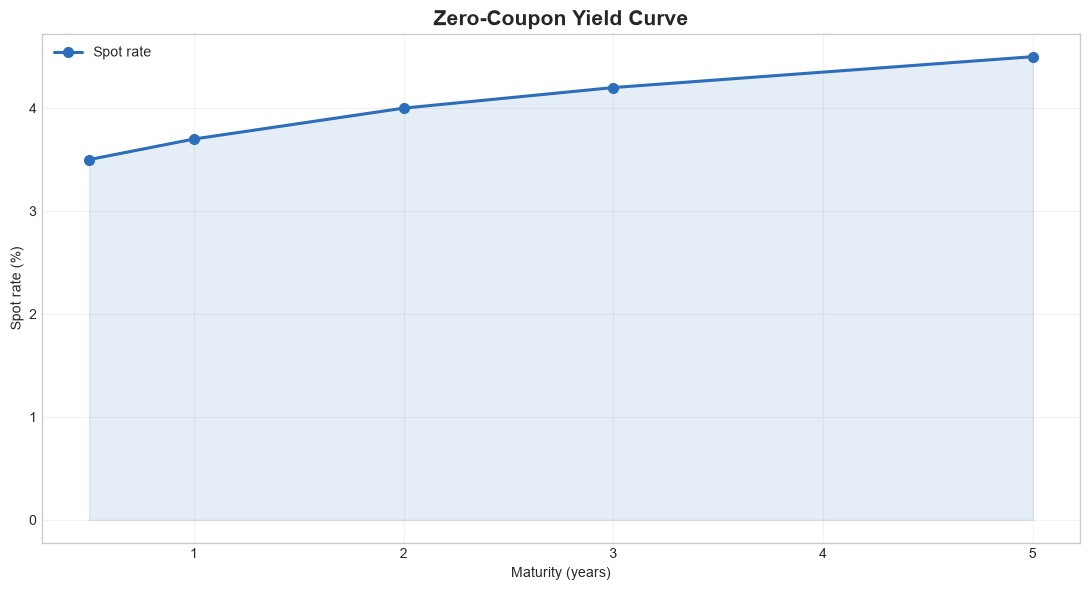

In [16]:
four_year_spot_rate = interpolate_spot_rate(
    curve=yield_curve,
    target_maturity_years=4.0,
)

two_to_five_year_forward_rate = (
    calculate_forward_rate(
        start_spot_rate=0.040,
        end_spot_rate=0.045,
        start_maturity_years=2.0,
        end_maturity_years=5.0,
        compounding_frequency=2,
    )
)

print(
    f"Interpolated four-year spot rate: "
    f"{four_year_spot_rate:.4%}"
)
print(
    f"Implied two-to-five-year forward rate: "
    f"{two_to_five_year_forward_rate:.4%}"
)

figure, axis = plot_yield_curve(
    curve=yield_curve
)

plt.show()

## 5. Yield-Curve Bootstrapping

Bootstrapping constructs a zero-coupon yield curve sequentially from market prices of coupon-bearing bonds.

For a bond maturing in period \(n\):

\[
P_n
=
C\sum_{i=1}^{n-1}DF_i
+
(F+C)DF_n
\]

The earlier discount factors are already known. Therefore, the new discount factor is isolated as:

\[
DF_n
=
\frac{
P_n-C\sum_{i=1}^{n-1}DF_i
}{
F+C
}
\]

Once the discount factor is obtained, the corresponding spot rate is:

\[
s_n
=
m\left(
DF_n^{-\frac{1}{n}}-1
\right)
\]

The procedure advances from the shortest maturity to the longest maturity, solving one new discount factor at a time.

In [17]:
from src.yield_curve import (
    ParBondQuote,
    bootstrap_par_bond_curve,
    calculate_discount_factor,
)

bootstrap_maturities = (0.5, 1.0, 1.5, 2.0)
known_spot_rates = (0.030, 0.033, 0.036, 0.039)
coupon_rates = (0.030, 0.035, 0.040, 0.045)

face_value = 100.0
frequency = 2

known_discount_factors = [
    calculate_discount_factor(
        spot_rate=spot_rate,
        maturity_years=maturity,
        compounding_frequency=frequency,
    )
    for maturity, spot_rate in zip(
        bootstrap_maturities,
        known_spot_rates,
        strict=True,
    )
]

bond_quotes = []

for period, (
    maturity,
    coupon_rate,
) in enumerate(
    zip(
        bootstrap_maturities,
        coupon_rates,
        strict=True,
    ),
    start=1,
):
    coupon_payment = (
        face_value * coupon_rate / frequency
    )

    market_price = (
        coupon_payment
        * sum(known_discount_factors[: period - 1])
        + (
            face_value + coupon_payment
        )
        * known_discount_factors[period - 1]
    )

    bond_quotes.append(
        ParBondQuote(
            maturity_years=maturity,
            annual_coupon_rate=coupon_rate,
            market_price=market_price,
            face_value=face_value,
            payments_per_year=frequency,
        )
    )

quote_table = pd.DataFrame(
    {
        "Maturity": [
            quote.maturity_years
            for quote in bond_quotes
        ],
        "Coupon rate": [
            quote.annual_coupon_rate
            for quote in bond_quotes
        ],
        "Market price": [
            quote.market_price
            for quote in bond_quotes
        ],
    }
)

quote_table.style.format(
    {
        "Maturity": "{:.1f} years",
        "Coupon rate": "{:.4%}",
        "Market price": "${:,.4f}",
    }
)

,Maturity,Coupon rate,Market price
0,0.5 years,3.0000%,$100.0000
1,1.0 years,3.5000%,$100.1977
2,1.5 years,4.0000%,$100.5905
3,2.0 years,4.5000%,$101.1757


In [18]:
bootstrapped_curve = bootstrap_par_bond_curve(
    bond_quotes
)

bootstrap_comparison = pd.DataFrame(
    {
        "Maturity": bootstrap_maturities,
        "Original spot rate": known_spot_rates,
        "Bootstrapped spot rate": [
            point.spot_rate
            for point in bootstrapped_curve
        ],
        "Discount factor": [
            point.discount_factor
            for point in bootstrapped_curve
        ],
    }
)

bootstrap_comparison[
    "Difference"
] = (
    bootstrap_comparison["Bootstrapped spot rate"]
    - bootstrap_comparison["Original spot rate"]
)

bootstrap_comparison.style.format(
    {
        "Maturity": "{:.1f} years",
        "Original spot rate": "{:.6%}",
        "Bootstrapped spot rate": "{:.6%}",
        "Discount factor": "{:.8f}",
        "Difference": "{:.10f}",
    }
)

,Maturity,Original spot rate,Bootstrapped spot rate,Discount factor,Difference
0,0.5 years,3.000000%,3.000000%,0.98522167,-0.0000000000
1,1.0 years,3.300000%,3.300000%,0.96779914,-0.0000000000
2,1.5 years,3.600000%,3.600000%,0.94788722,0.0000000000
3,2.0 years,3.900000%,3.900000%,0.92565911,0.0000000000


## 6. Stochastic Interest-Rate Models

Interest rates evolve unpredictably through time. Short-rate models combine a deterministic mean-reversion component with a random diffusion component.

### Vasicek Model

\[
dr_t
=
\kappa(\theta-r_t)dt
+
\sigma dW_t
\]

where:

- \(r_t\) is the current short-term rate.
- \(\kappa\) is the speed of mean reversion.
- \(\theta\) is the long-term mean rate.
- \(\sigma\) is interest-rate volatility.
- \(dW_t\) is a Brownian-motion shock.

The model pulls rates toward \(\theta\), but it can generate negative rates.

### Cox-Ingersoll-Ross Model

\[
dr_t
=
\kappa(\theta-r_t)dt
+
\sigma\sqrt{r_t}\,dW_t
\]

The diffusion depends on \(\sqrt{r_t}\), reducing volatility when rates approach zero.

The Feller condition is:

\[
2\kappa\theta \geq \sigma^2
\]

When satisfied, the theoretical continuous-time CIR process remains strictly positive.

The simulations use Euler discretization and a fixed random seed to ensure reproducibility.

In [19]:
vasicek_parameters = VasicekParameters(
    initial_rate=0.04,
    mean_reversion_speed=0.60,
    long_term_mean=0.05,
    volatility=0.015,
)

cir_parameters = CIRParameters(
    initial_rate=0.04,
    mean_reversion_speed=0.60,
    long_term_mean=0.05,
    volatility=0.10,
)

simulation_years = 5.0
steps_per_year = 12
number_of_simulations = 10_000
random_seed = 42

vasicek_simulation = simulate_vasicek(
    parameters=vasicek_parameters,
    years=simulation_years,
    steps_per_year=steps_per_year,
    simulations=number_of_simulations,
    seed=random_seed,
)

cir_simulation = simulate_cir(
    parameters=cir_parameters,
    years=simulation_years,
    steps_per_year=steps_per_year,
    simulations=number_of_simulations,
    seed=random_seed,
)

vasicek_summary = summarize_simulation(
    vasicek_simulation
)

cir_summary = summarize_simulation(
    cir_simulation
)

simulation_summary = pd.DataFrame(
    {
        "Metric": [
            "Mean terminal rate",
            "Median terminal rate",
            "Standard deviation",
            "5th percentile",
            "95th percentile",
            "Minimum rate",
            "Maximum rate",
        ],
        "Vasicek": [
            vasicek_summary.mean_terminal_rate,
            vasicek_summary.median_terminal_rate,
            vasicek_summary.standard_deviation,
            vasicek_summary.fifth_percentile,
            vasicek_summary.ninety_fifth_percentile,
            vasicek_summary.minimum_rate,
            vasicek_summary.maximum_rate,
        ],
        "CIR": [
            cir_summary.mean_terminal_rate,
            cir_summary.median_terminal_rate,
            cir_summary.standard_deviation,
            cir_summary.fifth_percentile,
            cir_summary.ninety_fifth_percentile,
            cir_summary.minimum_rate,
            cir_summary.maximum_rate,
        ],
    }
)

print(
    "CIR Feller condition satisfied:",
    cir_feller_condition(cir_parameters),
)

simulation_summary.style.format(
    {
        "Vasicek": "{:.4%}",
        "CIR": "{:.4%}",
    }
)

CIR Feller condition satisfied: True


,Metric,Vasicek,CIR
0,Mean terminal rate,4.9340%,4.9295%
1,Median terminal rate,4.9280%,4.6417%
2,Standard deviation,1.3922%,2.0486%
3,5th percentile,2.6353%,2.0767%
4,95th percentile,7.2066%,8.7189%
5,Minimum rate,-0.4963%,0.3703%
6,Maximum rate,10.0875%,15.9537%


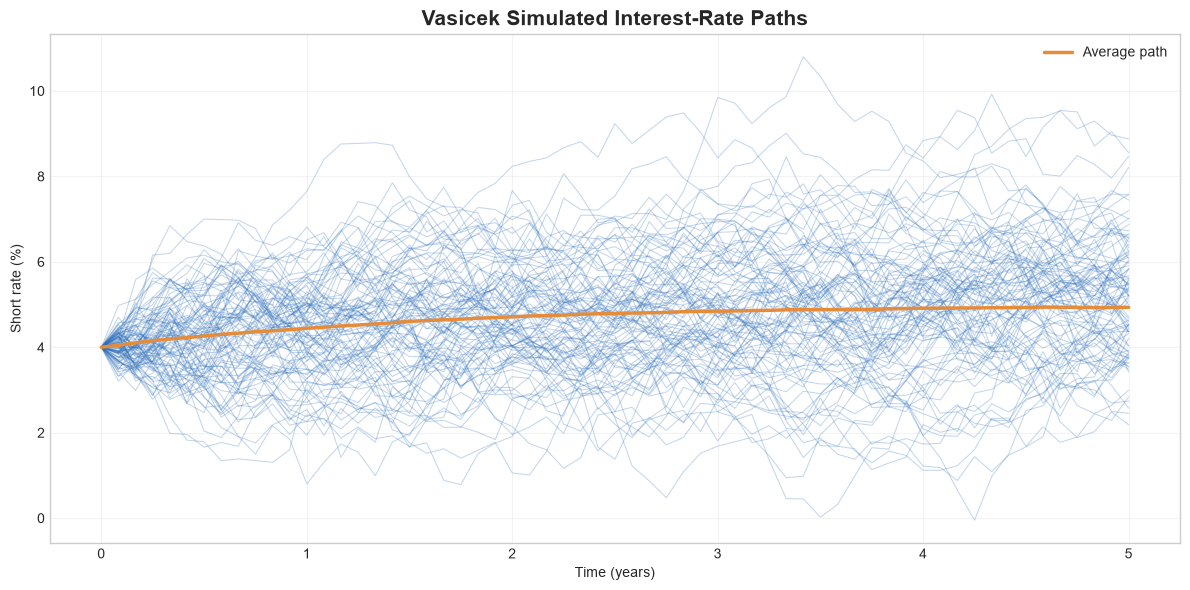

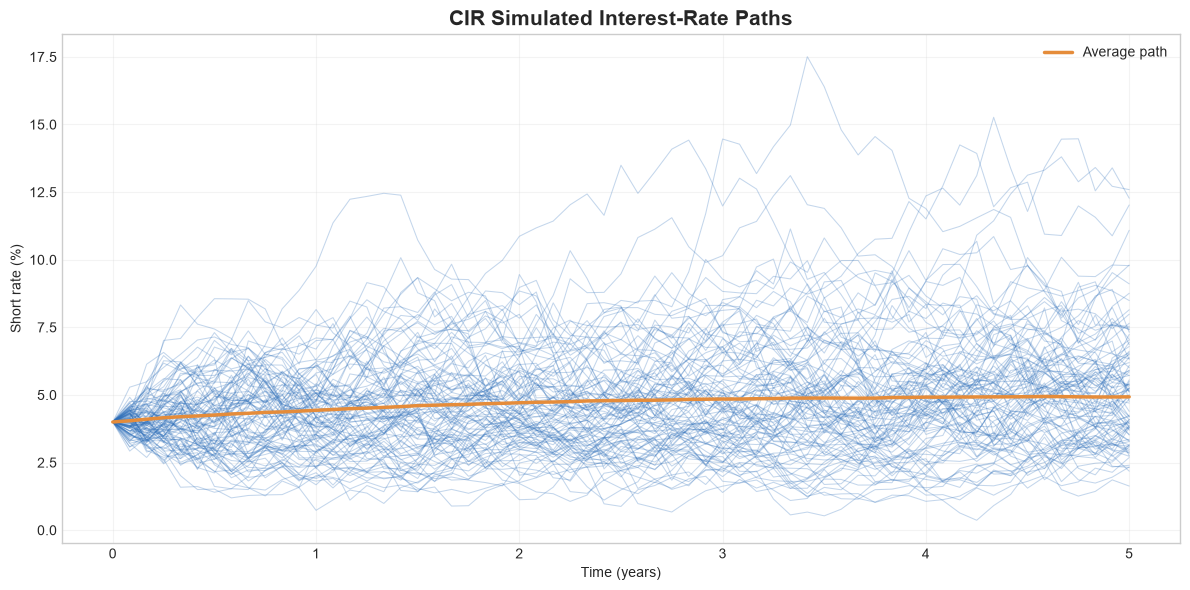

In [20]:
figure, axis = plot_rate_paths(
    simulation=vasicek_simulation,
    paths_to_show=100,
)

plt.show()

figure, axis = plot_rate_paths(
    simulation=cir_simulation,
    paths_to_show=100,
)

plt.show()

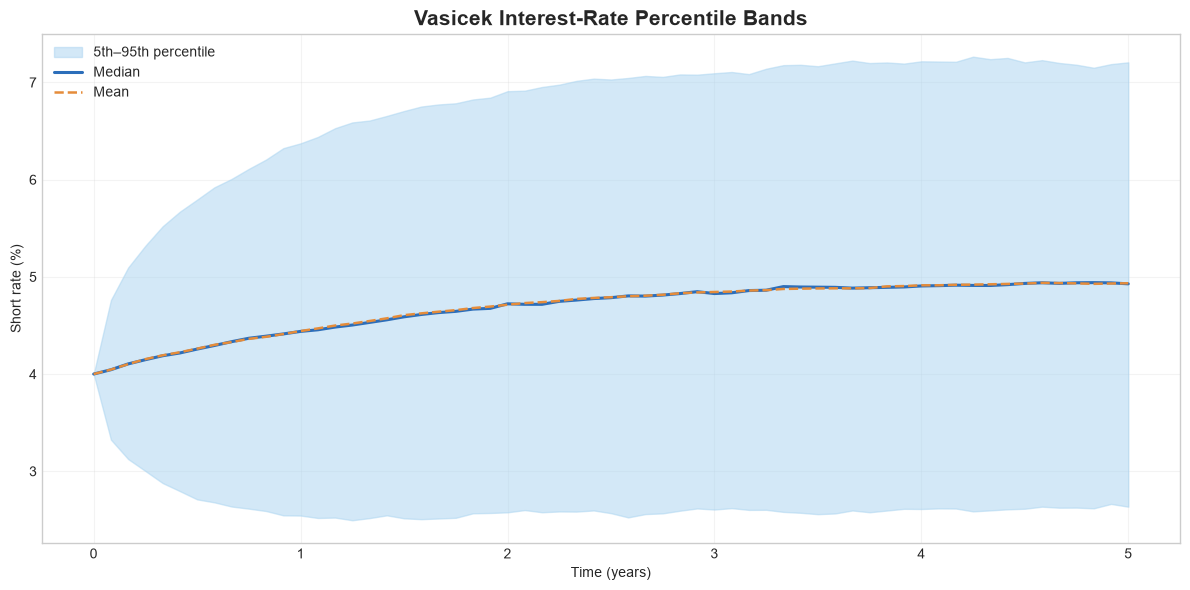

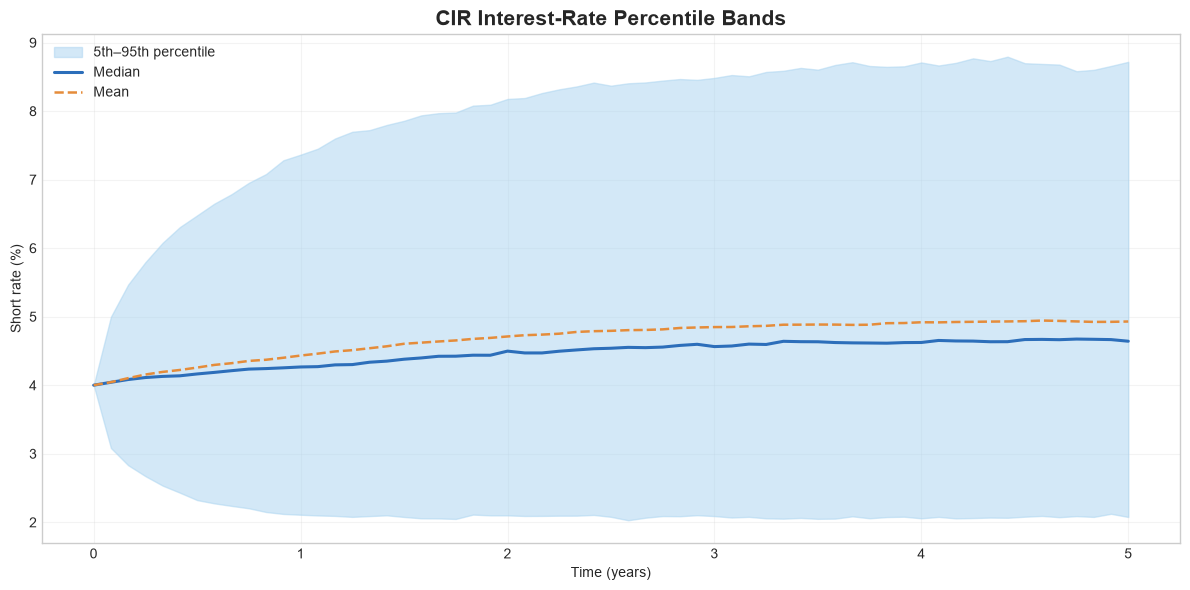

In [21]:
figure, axis = plot_rate_percentile_bands(
    simulation=vasicek_simulation,
    lower_percentile=5.0,
    upper_percentile=95.0,
)

plt.show()

figure, axis = plot_rate_percentile_bands(
    simulation=cir_simulation,
    lower_percentile=5.0,
    upper_percentile=95.0,
)

plt.show()

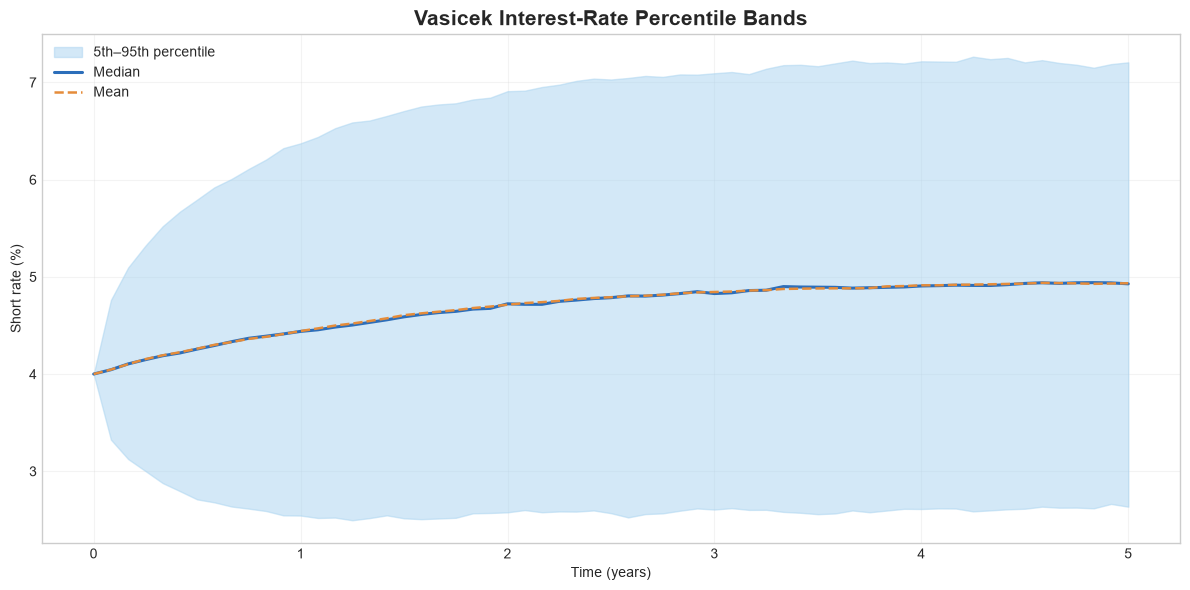

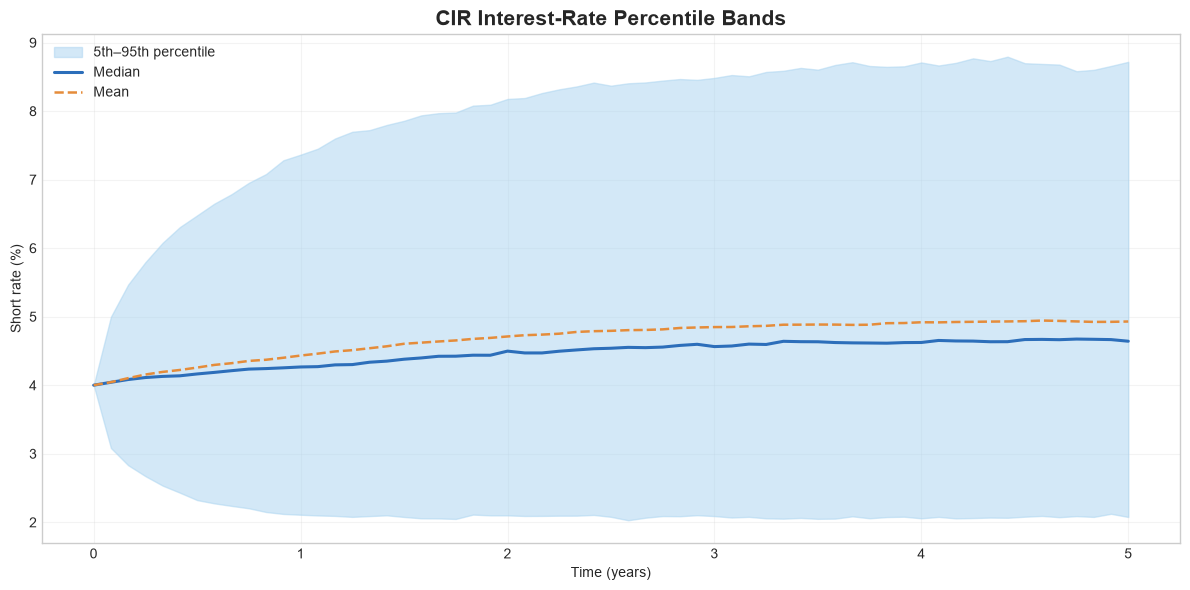

In [22]:
figure, axis = plot_rate_percentile_bands(
    simulation=vasicek_simulation,
    lower_percentile=5.0,
    upper_percentile=95.0,
)

plt.show()

figure, axis = plot_rate_percentile_bands(
    simulation=cir_simulation,
    lower_percentile=5.0,
    upper_percentile=95.0,
)

plt.show()

In [23]:
integrated_summary = pd.DataFrame(
    {
        "Area": [
            "Bond pricing",
            "Yield analysis",
            "Interest-rate risk",
            "Yield curve",
            "Stochastic modeling",
            "Software validation",
        ],
        "Key result": [
            f"Coupon bond value: ${coupon_bond_price:,.2f}",
            (
                "YTM at $950 market price: "
                f"{yield_metrics.yield_to_maturity:.4%}"
            ),
            (
                "Modified duration: "
                f"{sensitivity_metrics.modified_duration:.4f}; "
                f"DV01: ${sensitivity_metrics.dv01:.4f}"
            ),
            (
                "4-year interpolated spot rate: "
                f"{four_year_spot_rate:.4%}"
            ),
            (
                "10,000 Vasicek and CIR scenarios "
                "over five years"
            ),
            "197 automated tests passed",
        ],
    }
)

integrated_summary

,Area,Key result
0,Bond pricing,"Coupon bond value: $1,044.91"
1,Yield analysis,YTM at $950 market price: 6.1776%
2,Interest-rate risk,Modified duration: 4.4107; DV01: $0.4609
3,Yield curve,4-year interpolated spot rate: 4.3500%
4,Stochastic modeling,"10,000 Vasicek and CIR scenarios over five years"
5,Software validation,197 automated tests passed


## 7. Conclusions

This project developed an integrated quantitative fixed-income analytics engine.

### Main Findings

1. **Bond valuation**

   The five-year bond with a 5% annual coupon and a 4% market yield trades above face value because its coupon rate exceeds the required market return.

2. **Yield to Maturity**

   A market price below face value produces a YTM above the coupon rate because the investor receives both coupon income and a capital gain at maturity.

3. **Interest-rate sensitivity**

   Duration provides a first-order estimate of price sensitivity. Convexity materially improves the approximation when interest-rate movements become larger.

4. **Yield-curve analysis**

   Spot rates, discount factors, interpolated rates, and implied forward rates describe the term structure of interest rates and support consistent cash-flow valuation.

5. **Bootstrapping**

   The sequential bootstrapping procedure successfully recovers zero-coupon spot rates from coupon-bearing bond prices.

6. **Stochastic rate modeling**

   Vasicek and CIR generate alternative future interest-rate scenarios with mean reversion. Vasicek permits negative rates, while CIR incorporates a square-root diffusion and preserves non-negative simulated rates under the implemented truncation scheme.

7. **Software quality**

   The analytical engine is modular, reproducible, documented, and validated through 197 automated tests.

### Model Limitations

- The analysis assumes deterministic bond cash flows.
- Credit risk, liquidity risk, taxes, and transaction costs are excluded.
- The bonds contain no embedded options.
- Linear interpolation is used between observed curve points.
- Vasicek and CIR parameters are illustrative rather than calibrated to current market data.
- Euler discretization introduces numerical approximation error.
- Simulated scenarios are model-dependent and do not guarantee future outcomes.

### Final Interpretation

The project connects financial mathematics with numerical methods, Monte Carlo simulation, data visualization, testing, and software engineering. It provides a reproducible foundation for fixed-income valuation, interest-rate risk analysis, and future quantitative-finance applications.

---

> The results are intended for educational and quantitative research purposes and do not constitute investment advice.